In [44]:
from geospatial_functions import find_SA2
import pandas as pd
import geopandas as gpd

In [45]:
data_path = '../data/geospatial_data/SA2_2021_AUST_GDA2020/data.shp'
AusBS_Zones = gpd.read_file(data_path)

In [46]:
df = pd.read_csv("../data/properties_db/properties.csv")
df = df.drop(["Unnamed: 0"], axis=1)

df["SA2"] = df.apply(
    lambda row: find_SA2(AusBS_Zones, row["latitude"], row["longitude"]),
    axis=1,
)

df

,id,url,latitude,longitude,street_address,suburb,postcode,state,activated_at,weekly_rent_number,...,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,n_photos,walkability_score,added_at,SA2
0,515812,https://www.rent.com.au/property/108-126-chape...,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,vic,2026-05-27T08:58:04.000+08:00,550.0,...,False,False,False,False,False,{},6,"{""id"": 328136, ""transit_category"": ""excellent_...",2026-09-08 01:20:50,St Kilda East
1,802350,https://www.rent.com.au/property/24-barkly-pl-...,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,vic,2026-06-25T07:42:51.000+08:00,360.0,...,False,False,False,False,False,"{""airconditioning"": [""split system"", ""air-cond...",14,"{""id"": 239384, ""transit_category"": ""riders_par...",2026-09-07 21:14:45,Carlton
2,802356,https://www.rent.com.au/property/45-victoria-p...,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,vic,2026-06-19T08:05:47.000+08:00,360.0,...,False,False,False,False,False,{},20,"{""id"": 66149, ""transit_category"": ""riders_para...",2026-09-07 21:36:57,Collingwood
3,802372,https://www.rent.com.au/property/116-130-main-...,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,vic,2026-01-27T07:04:43.000+08:00,250.0,...,False,False,False,False,False,{},12,"{""id"": 67020, ""transit_category"": ""good_transi...",2026-09-07 23:09:44,Kingsbury
4,802379,https://www.rent.com.au/property/117-60-waverl...,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,vic,2026-05-01T14:55:39.000+08:00,540.0,...,False,False,False,False,False,{},12,"{""id"": 349530, ""transit_category"": ""excellent_...",2026-09-07 23:13:36,Malvern East
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9215,6482075,https://www.rent.com.au/property/910-14-david-...,-37.815459,145.011154,"910/14 David Street,",richmond,3121,vic,2026-09-07T17:41:11.000+08:00,625.0,...,False,False,False,False,False,{},11,"{""id"": 4707092, ""transit_category"": ""excellent...",2026-09-08 00:39:44,Richmond - North
9216,6482078,https://www.rent.com.au/property/31-berkeley-d...,-38.229818,144.347552,"31 Berkeley Drive,",armstrong creek,3217,vic,2026-09-07T17:47:58.000+08:00,525.0,...,False,False,False,False,False,{},9,"{""id"": 4707095, ""transit_category"": ""minimal_t...",2026-09-07 20:34:39,Charlemont
9217,6482082,https://www.rent.com.au/property/35-flannery-c...,-38.211548,144.369526,"35 Flannery Circuit,",charlemont,3217,vic,2026-09-07T17:55:57.000+08:00,580.0,...,False,False,False,False,False,{},17,"{""id"": 4707099, ""transit_category"": ""minimal_t...",2026-09-07 21:21:52,Charlemont
9218,6482085,https://www.rent.com.au/property/3-wight-st-ky...,-36.312810,145.037700,"3 Wight Street,",kyabram,3620,vic,2026-09-07T18:11:04.000+08:00,480.0,...,False,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",11,"{""id"": 4707102, ""transit_category"": ""minimal_t...",2026-09-07 23:02:02,Kyabram


342 of 361 Greater Melbourne SA2s have rent data
134 SA2s in df fall outside Greater Melbourne


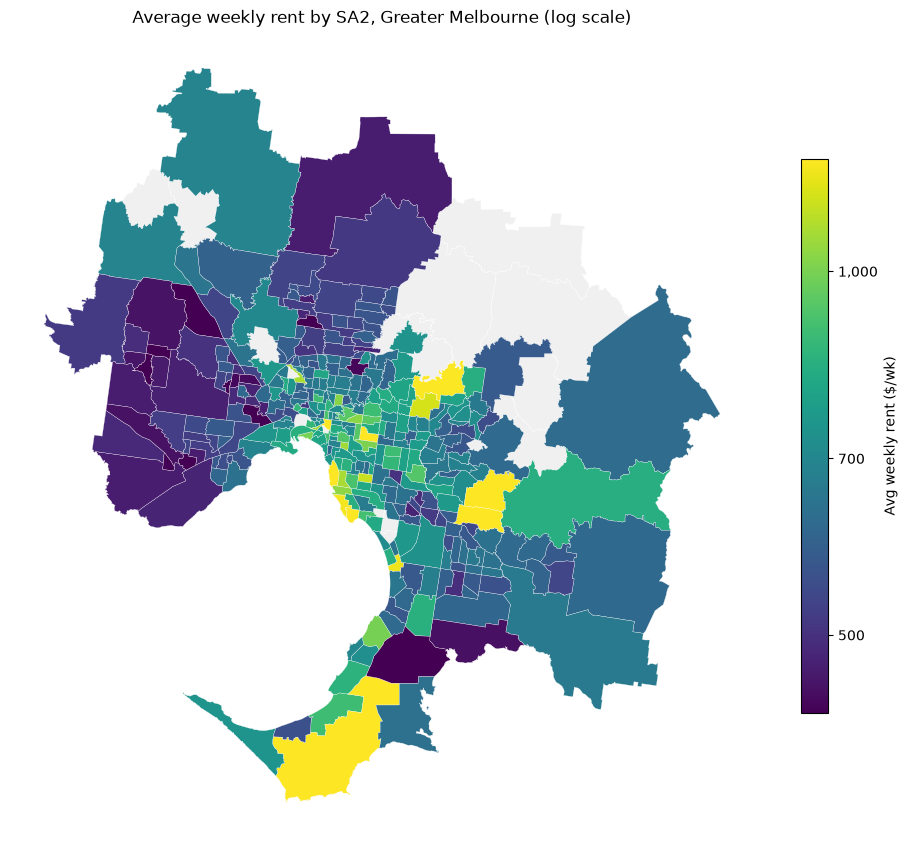

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

rent_by_sa2 = (
    df.groupby("SA2")["weekly_rent_number"]
      .agg(avg_rent="mean", n_properties="size")
      .reset_index()
)

# Greater Melbourne GCCSA only
zones = AusBS_Zones[AusBS_Zones["GCC_NAME21"] == "Greater Melbourne"].copy()
if zones.empty:
    raise ValueError(f"No match. GCC names present: {sorted(AusBS_Zones['GCC_NAME21'].unique())}")

merged = zones.merge(rent_by_sa2, left_on="SA2_NAME21", right_on="SA2", how="left")

matched = merged["avg_rent"].notna().sum()
print(f"{matched} of {len(zones)} Greater Melbourne SA2s have rent data")
print(f"{len(rent_by_sa2) - matched} SA2s in df fall outside Greater Melbourne")

merged = merged[~merged.geometry.is_empty & merged.geometry.notna()]
plot_data = merged[merged["avg_rent"].notna() & (merged["avg_rent"] > 0)]
if plot_data.empty:
    raise ValueError("No SA2s matched — check the join keys before plotting")

vmin, vmax = plot_data["avg_rent"].quantile([0.02, 0.98])
norm = LogNorm(vmin=vmin, vmax=vmax, clip=True)

fig, ax = plt.subplots(figsize=(12, 12))
merged.plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
plot_data.plot(
    column="avg_rent",
    cmap="viridis",
    norm=norm,
    legend=True,
    legend_kwds={"label": "Avg weekly rent ($/wk)", "shrink": 0.6},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

cbar = fig.axes[-1]
ticks = [t for t in [150, 200, 300, 400, 500, 700, 1000, 1500, 2000, 3000] if vmin <= t <= vmax]
if ticks:
    cbar.set_yticks(ticks)
    cbar.set_yticklabels([f"{t:,}" for t in ticks])
    cbar.minorticks_off()

ax.set_title("Average weekly rent by SA2, Greater Melbourne (log scale)")
ax.set_axis_off()
plt.show()

342 of 361 Greater Melbourne SA2s have listings
total 7,701 listings | median 15 | max 198


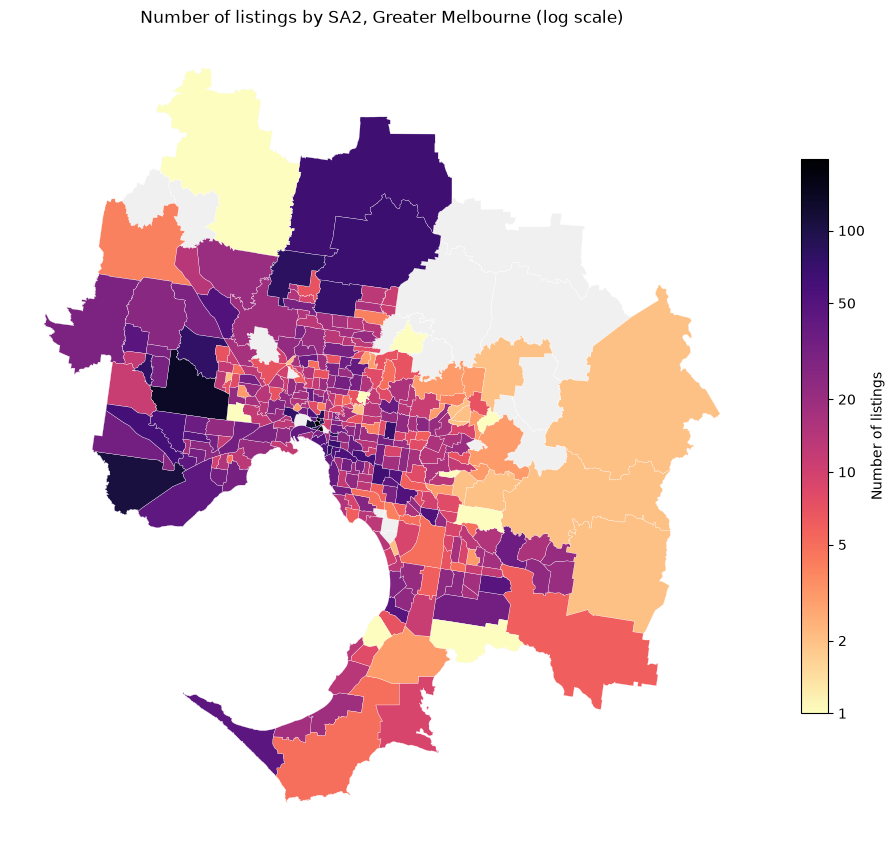

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

listings_by_sa2 = (
    df.groupby("SA2")
      .size()
      .reset_index(name="n_listings")
)

zones = AusBS_Zones[AusBS_Zones["GCC_NAME21"] == "Greater Melbourne"].copy()
if zones.empty:
    raise ValueError(f"No match. GCC names present: {sorted(AusBS_Zones['GCC_NAME21'].unique())}")

merged = zones.merge(listings_by_sa2, left_on="SA2_NAME21", right_on="SA2", how="left")
merged["n_listings"] = merged["n_listings"].fillna(0)

merged = merged[~merged.geometry.is_empty & merged.geometry.notna()]
plot_data = merged[merged["n_listings"] > 0]
if plot_data.empty:
    raise ValueError("No SA2s matched — check the join keys before plotting")

print(f"{len(plot_data)} of {len(merged)} Greater Melbourne SA2s have listings")
print(f"total {int(merged['n_listings'].sum()):,} listings | "
      f"median {plot_data['n_listings'].median():.0f} | max {int(plot_data['n_listings'].max())}")

norm = LogNorm(vmin=1, vmax=plot_data["n_listings"].max())

fig, ax = plt.subplots(figsize=(12, 12))
merged.plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
plot_data.plot(
    column="n_listings",
    cmap="magma_r",
    norm=norm,
    legend=True,
    legend_kwds={"label": "Number of listings", "shrink": 0.6},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

cbar = fig.axes[-1]
ticks = [t for t in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000] if t <= plot_data["n_listings"].max()]
cbar.set_yticks(ticks)
cbar.set_yticklabels([str(t) for t in ticks])
cbar.minorticks_off()

ax.set_title("Number of listings by SA2, Greater Melbourne (log scale)")
ax.set_axis_off()
plt.show()